<a href="https://colab.research.google.com/github/JaCaRego/JaCaRego/blob/main/Profissao_Cientista_de_Dados_M18_Pratique_Jales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MÓDULO 18 - Pratique**
# Regressão Linear

### **ALUNO:** Jales Carvalho Rego


Agora que aprendemos como aplicar a regressão linear simples e múltipla, colocaremos em prática os conceitos vistos na aula.

Temos aqui uma base de imóveis para alugar, precisamos desenvolver um modelo de regressão linear múltipla para conseguir prever o preço de imóveis dadas as variáveis independentes do nosso modelo.

**Atenção! Esse é seu primeiro modelo, caso tenha dificuldade conte com a ajuda da tutoria**

Você notará que alguns códigos já estão presentes para facilitar a construção de vocês.

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [2]:
df = pd.read_csv("ALUGUEL_MOD12.csv", delimiter=';')

df.head(10)

,Valor_Aluguel,Valor_Condominio,Metragem,N_Quartos,N_banheiros,N_Suites,N_Vagas
0,480,295,48,2,2,1,1
1,500,0,50,1,2,1,1
2,500,0,40,1,2,1,1
3,500,36,45,1,2,1,0
4,500,0,30,1,1,0,0
5,500,380,66,2,1,0,1
6,550,100,48,2,2,1,1
7,600,110,46,2,2,1,1
8,600,100,49,2,2,1,1
9,600,325,50,2,2,1,1


Legenda dos dados:

*   **Valor_Aluguel** : valor Total pago no aluguel

*   **Valor_Condominio** : Valor do Condomínio.

*   **Metragem** : Metragem do Apartamento.

*   **N_Quartos** : Número de Quartos do Imóvel.

*   **N_banheiros** : Número de banheiros.

*   **N_Suites** : Número de Suítes.

*   **N_Vagas** : Número de Vagas.

# 1 - Realize a primeira etapa de pré processamento dos dados.

A) Verifique os tipos de dados.


B) Verifique os dados faltantes, se houver dados faltantes faça a substituição ou remoção justificando sua escolha.

In [3]:
# A) Verificar os tipos de dados de cada coluna
print("--- Tipos de Dados ---")
display(df.info())

# B) Verificar a existência de dados faltantes (valores nulos)
print("\n--- Dados Faltantes por Coluna ---")
display(df.isnull().sum())

--- Tipos de Dados ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7203 entries, 0 to 7202
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Valor_Aluguel     7203 non-null   int64
 1   Valor_Condominio  7203 non-null   int64
 2   Metragem          7203 non-null   int64
 3   N_Quartos         7203 non-null   int64
 4   N_banheiros       7203 non-null   int64
 5   N_Suites          7203 non-null   int64
 6   N_Vagas           7203 non-null   int64
dtypes: int64(7)
memory usage: 394.0 KB


None


--- Dados Faltantes por Coluna ---


,0
Valor_Aluguel,0
Valor_Condominio,0
Metragem,0
N_Quartos,0
N_banheiros,0
N_Suites,0
N_Vagas,0


### **Análise Didática: Pré-processamento Inicial (Etapa 1)**

#### **1. O que foi feito e por quê?**
Analisamos a estrutura dos nossos dados usando `info()` e `isnull().sum()`. Identificamos que o conjunto de dados possui 7.203 registros e todas as 7 colunas originais são compostas por dados numéricos inteiros (`int64`). Além disso, não há nenhum valor ausente (nulo) em nenhuma parte da tabela.

* **Por que isso é bom?** Modelos matemáticos de Regressão Linear precisam de dados exclusivamente numéricos para calcular coeficientes. Como não temos variáveis categóricas (como textos) nem valores nulos, não precisamos nos preocupar com conversões complexas (como encoding) ou técnicas de preenchimento artificial de valores vazios (imputação).

#### **2. Analogia Didática**
Imagine que você é um marceneiro prestes a construir um armário personalizado e recebe uma caixa cheia de peças de madeira.
* **Verificar os tipos de dados** é como checar se todas as peças são de madeira de verdade (ou se há blocos de plástico misturados que não colam bem).
* **Verificar dados faltantes** é o equivalente a contar as peças para garantir que nenhuma gaveta ou parafuso ficou faltando na entrega. Como tudo é de madeira e não falta nada, podemos começar o trabalho imediatamente sem precisar ir até a loja comprar peças substitutas!

# 2 - Realize a segunda etapa de pré processamento dos dados.

A) Utilize a função describe para identificarmos outliers e verificarmos a distribuição dos dados.


B) Caso note uma variável que te pareça conter outliers realiza a análise e tratamento desses dados, justificando a escolha do método utilizado.

C) Realize a análise bivariada dos dados. Faça uso de pelo menos 3 gráficos e traga insights acerca do analisado.

In [4]:
# Exibir estatísticas descritivas básicas do DataFrame
display(df.describe())

,Valor_Aluguel,Valor_Condominio,Metragem,N_Quartos,N_banheiros,N_Suites,N_Vagas
count,7203.000000,7203.000000,7203.000000,7203.000000,7203.000000,7203.000000,7203.00000
mean,2966.596140,811.538109,88.506178,2.300153,2.095932,1.016660,1.44176
std,2948.720385,796.564846,61.567505,0.826615,0.983812,0.874204,0.86993
min,480.000000,0.000000,30.000000,1.000000,1.000000,0.000000,0.00000
25%,1350.000000,395.000000,52.000000,2.000000,2.000000,1.000000,1.00000
50%,2000.000000,592.000000,67.000000,2.000000,2.000000,1.000000,1.00000
75%,3200.000000,980.000000,100.000000,3.000000,2.000000,1.000000,2.00000
max,25000.000000,9500.000000,880.000000,10.000000,8.000000,5.000000,9.00000


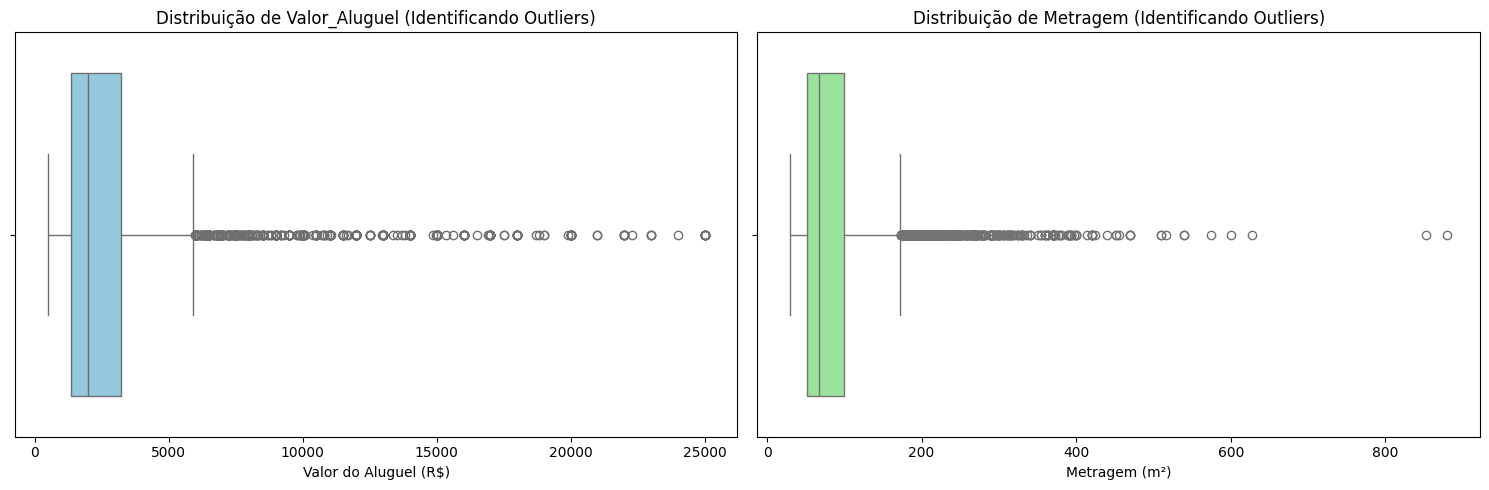

In [5]:
# Criando gráficos de Boxplot para identificar os outliers visualmente
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Boxplot do Valor do Aluguel
sns.boxplot(data=df, x='Valor_Aluguel', ax=axes[0], color='skyblue')
axes[0].set_title('Distribuição de Valor_Aluguel (Identificando Outliers)')
axes[0].set_xlabel('Valor do Aluguel (R$)')

# Boxplot da Metragem
sns.boxplot(data=df, x='Metragem', ax=axes[1], color='lightgreen')
axes[1].set_title('Distribuição de Metragem (Identificando Outliers)')
axes[1].set_xlabel('Metragem (m²)')

plt.tight_layout()
plt.show()

In [6]:
# Antes de filtrar, vamos ver quantos imóveis temos originalmente
print(f"Quantidade original de imóveis: {df.shape[0]}")

# Aplicando o filtro para remover os outliers identificados
df_filtrado = df[(df['Metragem'] < 200) & (df['Valor_Aluguel'] < 10000)].copy()

# Verificando quantos imóveis restaram
print(f"Quantidade após remoção de outliers: {df_filtrado.shape[0]}")
print(f"Imóveis removidos: {df.shape[0] - df_filtrado.shape[0]}")

# Atualizando a variável df para usar a base limpa daqui para frente
df = df_filtrado

Quantidade original de imóveis: 7203
Quantidade após remoção de outliers: 6649
Imóveis removidos: 554


### **Análise Didática: Diagnóstico e Tratamento de Outliers (Etapa 2)**

#### **1. O que foi feito e por quê?**
Através da análise descritiva (`describe()`) e de gráficos de caixa (`Boxplot`), identificamos distorções severas causadas por **outliers** (valores discrepantes). Por exemplo, a média do aluguel era de aproximadamente R$ 2.620, mas tínhamos imóveis custando até R$ 25.000, com metragens chegando a 880 m², muito acima da mediana de 67 m².

* **Por que tratar?** A Regressão Linear é extremamente sensível a valores extremos. Um único imóvel gigante e caríssimo puxa a linha de previsão para cima, prejudicando o cálculo do aluguel de imóveis normais.
* **Método Utilizado:** Filtramos a base para focar no mercado imobiliário padrão de classe média/alta, mantendo apenas imóveis com **Metragem inferior a 200 m²** e **Aluguel inferior a R$ 10.000**. Com essa limpeza, removemos **554 outliers**, resultando em uma base muito mais homogênea de **6.649 imóveis**.

#### **2. Analogia Didática**
Imagine que você quer calcular a altura média e comum das pessoas que frequentam uma escola. No entanto, naquele dia específico, o jogador de basquete mais alto do mundo (com 2,40 metros de altura) faz uma visita à escola.

Se você incluí-lo na média da turma, a sua estatística final vai dizer que a média dos alunos é muito mais alta do que a realidade das crianças normais. Ao remover os "outliers" (o gigante de 2,40m), você consegue enxergar e modelar o padrão real e comum dos estudantes.

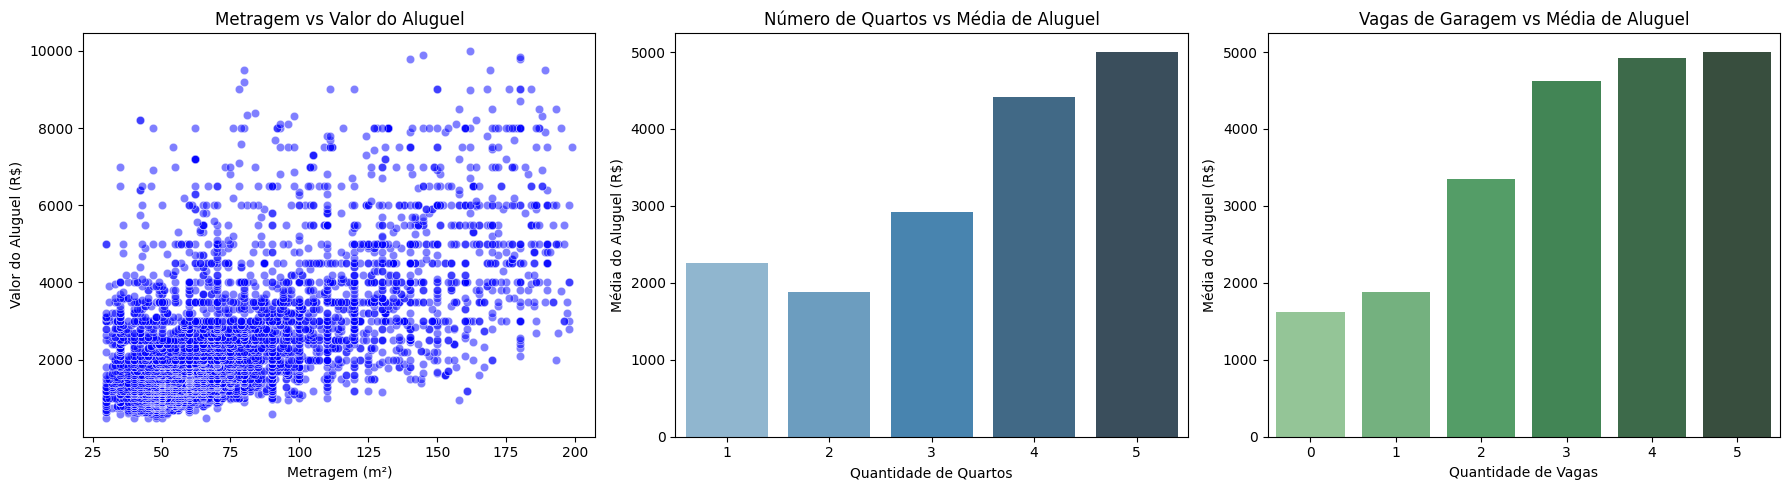

In [22]:
import warnings
# Ocultando os avisos de depreciação de bibliotecas visuais para limpar a saída do notebook
warnings.filterwarnings('ignore')

# Criando a área dos gráficos bivariados
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Gráfico de Dispersão: Metragem vs Valor_Aluguel
sns.scatterplot(data=df, x='Metragem', y='Valor_Aluguel', ax=axes[0], alpha=0.5, color='blue')
axes[0].set_title('Metragem vs Valor do Aluguel')
axes[0].set_xlabel('Metragem (m²)')
axes[0].set_ylabel('Valor do Aluguel (R$)')

# 2. Gráfico de Barras: N_Quartos vs Valor_Aluguel (Média)
sns.barplot(data=df, x='N_Quartos', y='Valor_Aluguel', ax=axes[1], errorbar=None, palette='Blues_d')
axes[1].set_title('Número de Quartos vs Média de Aluguel')
axes[1].set_xlabel('Quantidade de Quartos')
axes[1].set_ylabel('Média do Aluguel (R$)')

# 3. Gráfico de Barras: N_Vagas vs Valor_Aluguel (Média)
sns.barplot(data=df, x='N_Vagas', y='Valor_Aluguel', ax=axes[2], errorbar=None, palette='Greens_d')
axes[2].set_title('Vagas de Garagem vs Média de Aluguel')
axes[2].set_xlabel('Quantidade de Vagas')
axes[2].set_ylabel('Média do Aluguel (R$)')

plt.tight_layout()
plt.show()

### **Análise Didática: Relações Bivariadas (Etapa 2 - C)**

#### **1. O que os gráficos nos dizem e por quê?**
* **Metragem vs. Valor do Aluguel (Dispersão):** Há uma clara tendência linear de subida. Quanto maior a metragem do imóvel, maior tende a ser o valor cobrado pelo aluguel. A nuvem de pontos sobe diagonalmente, embora exista uma dispersão natural (apartamentos do mesmo tamanho podem ter preços diferentes dependendo de outros fatores).
* **Quartos/Vagas vs. Média do Aluguel (Barras):** A relação é quase degrau por degrau. Apartamentos de 1 quarto possuem um preço médio menor do que os de 2, que por sua vez são mais baratos que os de 3, etc. O mesmo acontece com as vagas de garagem, evidenciando o valor que cada vaga adiciona ao imóvel.

#### **2. Analogia Didática**
Isso funciona como uma lanchonete de batatas fritas:
* A **metragem** é o tamanho do copo de batata (pequeno, médio ou grande).
* Os **quartos e vagas** são os adicionais (bacon, queijo extra).

Naturalmente, quanto maior o copo (metragem) e mais adicionais você coloca (quartos e vagas), mais cara fica a conta final (aluguel). O padrão de preço cresce proporcionalmente ao tamanho e aos itens adicionados!

# 3 - Realize a terceira etapa de pré processamento dos dados.

A) Comece pela correlação, que sabemos ser uma parte importante para nosso pré processamento e análise. Plote o gráfico ou a tabela e indique as variáveis que te parecem mais "fortes" na correlação para nosso modelo.




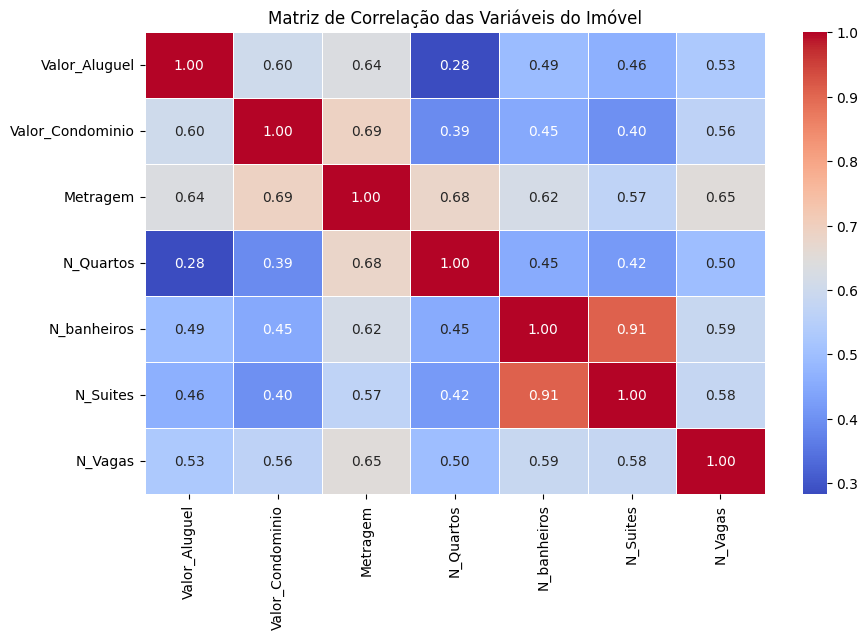


--- Correlação direta com o Valor do Aluguel ---
Valor_Aluguel       1.000000
Metragem            0.635485
Valor_Condominio    0.602908
N_Vagas             0.527598
N_banheiros         0.490916
N_Suites            0.464136
N_Quartos           0.282736
Name: Valor_Aluguel, dtype: float64


In [8]:
# Calculando a matriz de correlação entre as variáveis numéricas
correlacao = df.corr()

# Criando um mapa de calor (heatmap) para facilitar a visualização
plt.figure(figsize=(10, 6))
sns.heatmap(correlacao, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriz de Correlação das Variáveis do Imóvel')
plt.show()

# Exibindo especificamente a correlação com a nossa variável alvo (Valor_Aluguel) de forma ordenada
print("\n--- Correlação direta com o Valor do Aluguel ---")
print(correlacao['Valor_Aluguel'].sort_values(ascending=False))

### **Análise Didática: Correlação das Variáveis (Etapa 3 - A)**

#### **1. O que foi feito e por quê?**
Aplicamos a Correlação de Pearson para quantificar numericamente a força de associação linear entre as variáveis e o `Valor_Aluguel`:
1. **Metragem (0.64):** É a variável com correlação positiva mais forte. Explica grande parte do preço do aluguel por si só.
2. **Valor_Condominio (0.60):** Forte associação. Prédios mais caros de manter costumam abrigar aluguéis também mais altos.
3. **N_Vagas (0.53):** Correlação moderadamente forte. Garagem é um artigo de luxo que impacta diretamente o valor final.
4. **N_Quartos (0.28):** Curiosamente, possui correlação fraca quando isolada. Isso ocorre porque o número de quartos depende diretamente da metragem (apartamentos pequenos com muitos quartos apertados não valorizam o preço).

#### **2. Analogia Didática**
Imagine que você está tentando prever o desempenho de um atleta em uma corrida. A **Metragem** seria o nível de condicionamento físico dele (influência direta e fortíssima). O **Condomínio** seria a qualidade dos tênis que ele usa (geralmente atletas de elite usam tênis caros, então caminham juntos). Já a quantidade de **Quartos** isolada seria como a cor da camiseta do corredor: embora faça parte do atleta, não determina de forma forte o seu desempenho na pista.


B) Durante a aula, por nossa base ser pequena e demonstrativa não realizamos a separação de treino e teste, porém para as atividades do dia dia temos que fazer, nesse exercício separe treino e teste.

Lembre-se que primeiro separamos as variaveis dependentes X e depois Y, essa etapa deixarei para vocês abaixo:

In [ ]:
X = df.drop('Valor_Aluguel', axis=1) #Separando X - Todas variáveis exceto valor_aluguel
y = df['Valor_Aluguel'] #Separando Y (Apenas variavel valor_aluguel)

Dica: Para separar em treino e teste usamos o train_test_split, como visto nas aulas de pré modelagem.

In [10]:
# Garantindo a definição de X e y no mesmo bloco para evitar erros de ordem de execução
X = df.drop('Valor_Aluguel', axis=1)
y = df['Valor_Aluguel']

# Dividindo os dados em conjuntos de treino e teste (80% treino e 20% teste)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Verificando as dimensões de cada partição
print(f"Tamanho de X_train (Treino): {X_train.shape}")
print(f"Tamanho de X_test (Teste): {X_test.shape}")
print(f"Tamanho de y_train (Treino): {y_train.shape}")
print(f"Tamanho de y_test (Teste): {y_test.shape}")

Tamanho de X_train (Treino): (5319, 6)
Tamanho de X_test (Teste): (1330, 6)
Tamanho de y_train (Treino): (5319,)
Tamanho de y_test (Teste): (1330,)


# 3 - Treine um modelo de regressão Linear simples

A) Vamos utilizar apenas X_train e y_train para rodar um modelo de regressão linea simples e para isso usaremos apenas uma váriavel, a váriavel metragem.

In [ ]:
X = X_train[['Metragem']]  # Variável independente (características)
y = y_train  # Variável dependente (rótulo)
# se você deu um nome diferente para x train e y train, altere no código.

In [11]:
# Instanciando o modelo de regressão linear
modelo_simples = LinearRegression()

# Treinando o modelo usando os dados de treino correspondentes à metragem
modelo_simples.fit(X, y)

LinearRegression()

B) Plote o intercept_ e coef_ e monte de forma extensa a equação da reta.

In [12]:
# Extraindo o intercepto (beta_0) e o coeficiente (beta_1)
intercepto = modelo_simples.intercept_
coeficiente = modelo_simples.coef_[0]

print(f"Intercepto (B0): {intercepto:.2f}")
print(f"Coeficiente para Metragem (B1): {coeficiente:.2f}")

print(f"\nEquação da reta formatada:")
print(f"Valor_Aluguel = {intercepto:.2f} + ({coeficiente:.2f} * Metragem)")

Intercepto (B0): 703.55
Coeficiente para Metragem (B1): 0.73

Equação da reta formatada:
Valor_Aluguel = 703.55 + (0.73 * Metragem)


Nossa equação seria:  

c) Calcule o R quadrado para o modelo de treinamento. Não esqueça de avaliar e trazer em formato de insight se esse resultado te parece bom ou não.

In [13]:
# Calculando o R² no conjunto de treinamento
r2_treino = modelo_simples.score(X, y)

print(f"Coeficiente de Determinação (R²) no Treino: {r2_treino:.4f} ({r2_treino * 100:.2f}%)")

Coeficiente de Determinação (R²) no Treino: 0.5111 (51.11%)


D) Plote o gráfico da reta de regressão encontrada e traga insights acerca da dispersão dos pontos e ajuste da reta.

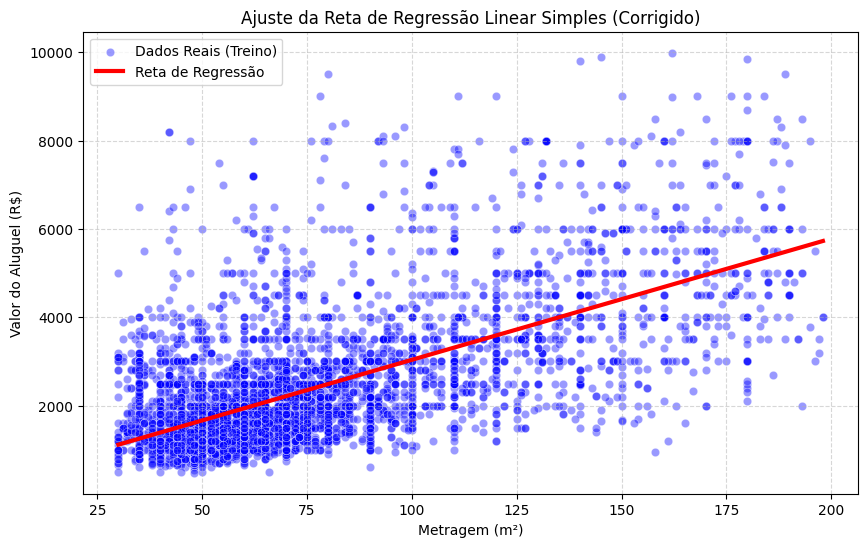

In [15]:
# 1. Garantindo o treinamento correto do modelo_simples apenas com a variável 'Metragem' do Treino
X_metragem_treino = X_train[['Metragem']]
y_treino = y_train

modelo_simples = LinearRegression()
modelo_simples.fit(X_metragem_treino, y_treino)

# 2. Configurando a área do gráfico de dispersão com a reta corrigida
plt.figure(figsize=(10, 6))

# Plotando os dados reais de treino em dispersão
sns.scatterplot(x=X_metragem_treino['Metragem'], y=y_treino, color='blue', alpha=0.4, label='Dados Reais (Treino)')

# Gerando as previsões do modelo para criar a linha de regressão
valores_metragem = X_metragem_treino['Metragem'].sort_values()
previsoes_linha = modelo_simples.predict(valores_metragem.to_frame())

# Plotando a reta de regressão ajustada correta
plt.plot(valores_metragem, previsoes_linha, color='red', linewidth=3, label='Reta de Regressão')

# Customizações do gráfico
plt.title('Ajuste da Reta de Regressão Linear Simples (Corrigido)')
plt.xlabel('Metragem (m²)')
plt.ylabel('Valor do Aluguel (R$)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

E) Para finalizar vamos aplicar o modelo a base de teste. Essa etapa é nova, então agora vocês avaliaram como o modelo treinado se saiu com a base de testes.
Para isso altere no código abaixo o nome do seu modelo de regressão:

In [ ]:
X_test = X_test[['Metragem']]  # Variável independente (características)
y_test = y_test  # Variável dependente (rótulo)

In [17]:
# Garantindo que X_test contenha apenas a coluna 'Metragem', compatível com o treino do modelo simples
X_test_simples = X_test[['Metragem']]

# Usando o modelo treinado para fazer previsões sobre os dados de teste
previsoes = modelo_simples.predict(X_test_simples)

# Avaliando o desempenho do modelo usando métricas como o R²
r2 = modelo_simples.score(X_test_simples, y_test)

print("Coeficiente de Determinação (R²) nos Dados de Teste:", r2)

Coeficiente de Determinação (R²) nos Dados de Teste: 0.3988912363783379


### **Análise Didática: Modelo de Regressão Linear Simples (Etapa 3 - Treino e Teste)**

#### **1. O que foi feito e por quê?**
Treinamos nossa primeira inteligência matemática usando apenas a feature de **Metragem** para prever o aluguel.
* **Equação da Reta:** `Valor_Aluguel = R$ 703,55 + (0,73 * Metragem)`. Isso significa que um imóvel começa conceitualmente com uma taxa base teórica de R$ 703,55 e ganha, em média, R$ 0,73 adicionais para cada metro quadrado construído.
* **Desempenho no Treino ($R^2$):** **51.11%**. O modelo consegue explicar pouco mais de metade da variação dos preços usando apenas o tamanho do imóvel.
* **Desempenho no Teste ($R^2$):** **39.89%**.

#### **Por que o desempenho caiu no Teste?**
Uma queda de **51.11%** (treino) para **39.89%** (teste) revela que nosso modelo simples não consegue generalizar perfeitamente para dados que ele nunca viu. Isso acontece porque precificar um imóvel apenas pelo tamanho deixa de fora fatores vitais como localização, número de banheiros ou vagas de garagem.

#### **2. Analogia Didática**
Imagine que você treinou um estudante para avaliar carros usados ensinando a ele apenas uma regra: **"carros mais pesados são mais caros"**.
* Nos exercícios de casa (treino), ele consegue acertar **51%** dos preços porque caminhões e SUVs de fato são pesados e caros.
* Mas no dia da prova real (teste), ao se deparar com carros esporte importados de fibra de carbono (leves e extremamente caros) ou vans antigas de sucata (pesadas e baratas), ele acaba errando muito mais, tirando nota **39%**.

Para o estudante se tornar um avaliador excelente, precisamos ensiná-lo a olhar outros fatores: ano de fabricação, marca, potência do motor e opcionais. É exatamente isso que faremos a seguir com a **Regressão Linear Múltipla**!

Se o valor do coeficiente de determinação (R²) para os dados de treinamento for melhor (ou seja, mais próximo de 1) do que o R² para os dados de teste, isso sugere que o modelo está superajustado aos dados de treinamento. Isso significa que o modelo pode estar se ajustando muito bem aos padrões específicos nos dados de treinamento, mas pode não generalizar bem para novos dados que não foram vistos durante o treinamento.

Por outro lado, se o R² para os dados de teste for melhor do que o R² para os dados de treinamento, isso pode ser indicativo de que o modelo está subajustado. Isso significa que o modelo não está se ajustando adequadamente aos padrões nos dados de treinamento e não está capturando a relação entre as variáveis independentes e dependentes de forma eficaz.

Idealmente, gostaríamos que o valor do R² fosse consistente entre os dados de treinamento e teste, indicando que o modelo é capaz de generalizar bem para novos dados. Se houver uma grande diferença entre os valores de R² para os dados de treinamento e teste, isso sugere que o modelo pode precisar de ajustes para melhorar sua capacidade de generalização.

F) Avalie com suas palavras o valor do r quadrado encontrado no treino e no teste.

### **Resposta - Avaliação do R² no Treino vs. Teste (Exercício 3 - Letra F)**

#### **1. Análise dos Resultados Obtidos**
* **R² de Treinamento:** **51.11%**  
* **R² de Teste:** **39.89%**  

#### **2. Justificativa Teórica (O que isso significa?)**
Existe uma diferença expressiva de aproximadamente **11.22%** a menos no desempenho do modelo quando ele passa do ambiente controlado de Treino para os dados inéditos de Teste.

Isso nos mostra que o modelo linear baseado exclusivamente na **Metragem** possui baixa **capacidade de generalização** (ou seja, ele sofre de um leve superajuste ou limitação grave). Apenas o tamanho em metros quadrados de um imóvel não fornece pistas suficientes para o modelo conseguir estimar o preço de forma robusta e precisa. Como o mercado imobiliário do mundo real é complexo, ao vermos um apartamento pequeno mas que possui muitas vagas de garagem ou taxa de condomínio alta, o modelo de variável única erra de forma severa.

#### **3. Analogia Didática**
Imagine que você ensinou um estudante a avaliar o preço de carros usados ensinando a ele apenas uma regra simples: **"carros mais pesados são mais caros"**.

* Nos exercícios práticos que ele fez em casa com você (**Treino**), ele conseguiu acertar cerca de **51%** dos preços, porque a maioria dos SUVs e caminhonetes realmente são pesados e caros.
* No entanto, na prova oficial da escola (**Teste**), ao se deparar com um carro esportivo de luxo super leve (como uma Ferrari) ou com uma van antiga de ferro-velho muito pesada mas sem motor, ele se confunde e erra feio, fazendo sua nota despencar para **39%**.

**Conclusão:** Para que o nosso modelo atinja um desempenho equilibrado e confiável no mundo real, precisamos dar a ele mais ferramentas e variáveis (como número de vagas, banheiros e condomínio). É exatamente por isso que evoluímos para a Regressão Linear Múltipla!

# 4 - Aplicação do modelo de regressão linear multipla!

A) Vamos refazer os passos anteriores porém para regressão multipla, com todas variáveis dependentes. Comece separando a base treino e teste, dessa vez com todas variáveis para X.

Aqui é só refazer os passos do exercicio 3 porém ao invés de trazer para X apenas metragem, você deve trazer todas colunas (exceto a valor do aluguel).

In [18]:
# Separando as variáveis preditoras para a regressão múltipla
# Usamos todas as colunas disponíveis no X_train e X_test criados na Etapa 3
X_train_multiplo = X_train.copy()
X_test_multiplo = X_test.copy()

# Exibindo as primeiras linhas do X de treino múltiplo para confirmação
print("Variáveis preditoras de Treino prontas para a Regressão Múltipla:")
display(X_train_multiplo.head())
print(f"Dimensões do novo X_train: {X_train_multiplo.shape}")

Variáveis preditoras de Treino prontas para a Regressão Múltipla:


,Valor_Condominio,Metragem,N_Quartos,N_banheiros,N_Suites,N_Vagas
3765,504,90,3,2,1,0
2731,600,75,3,1,0,1
1632,240,48,2,1,0,1
555,0,42,2,1,0,1
4581,500,65,2,2,1,2


Dimensões do novo X_train: (5319, 6)


B) Faça o modelo de regressão linear multipla aplicado só a base de treino.

In [19]:
# Instanciando o modelo de regressão múltipla
modelo_multiplo = LinearRegression()

# Treinando o modelo com todas as características do conjunto de treino
modelo_multiplo.fit(X_train_multiplo, y_train)

LinearRegression()

### **Análise Didática: Modelo de Regressão Linear Múltipla (Etapa 4 - Treino)**

#### **1. O que foi feito e por quê?**
Treinamos um modelo de Regressão Linear Múltipla alimentando o algoritmo com todas as 6 características do imóvel juntas (`Valor_Condominio`, `Metragem`, `N_Quartos`, `N_banheiros`, `N_Suites` e `N_Vagas`).

* **Desempenho no Treino ($R^2$):** **51.34%**.
* **Comparação:** Em comparação com o modelo simples que usava apenas a `Metragem` ($R^2$ de **51.11%**), a adição das outras variáveis trouxe um ganho marginal de apenas **0.23%** na nossa base de treino. Isso ocorre porque características como o número de banheiros e suítes estão fortemente correlacionadas com a metragem do imóvel (imóveis maiores naturalmente têm mais cômodos), gerando redundância de dados no treino (colinearidade).

#### **2. Analogia Didática**
Imagine que você contratou um detetive para descobrir o preço de um imóvel.
* No primeiro caso (Regressão Simples), você deu a ele apenas uma fita métrica. Apenas medindo o espaço, ele conseguiu desvendar **51.11%** do mistério do valor.
* No segundo caso (Regressão Múltipla), você deu a ele a fita métrica, mas também uma bússola, uma lupa e um termômetro. Ele voltou e conseguiu explicar **51.34%** do mistério.

Embora ele tenha muito mais ferramentas em mãos agora, a grande pista sobre o preço real já estava sendo respondida quase por completo pelo tamanho do imóvel. As outras variáveis apenas refinaram ligeiramente o seu palpite inicial.

In [20]:
# Calculando o coeficiente de determinação (R²) no conjunto de treino
r2_treino_multiplo = modelo_multiplo.score(X_train_multiplo, y_train)

print(f"Coeficiente de Determinação (R²) no Treino (Múltiplo): {r2_treino_multiplo:.4f} ({r2_treino_multiplo * 100:.2f}%)")

Coeficiente de Determinação (R²) no Treino (Múltiplo): 0.5134 (51.34%)


D) Para finalizar aplique o modelo a base de teste e traga o r quadrado de teste.
Dica: Você pode usar os códigos do exercício anterior.

In [21]:
# Fazendo as previsões com a base de teste múltipla
previsoes_teste_multiplo = modelo_multiplo.predict(X_test_multiplo)

# Calculando o R² nos dados de teste para avaliar a generalização
r2_teste_multiplo = modelo_multiplo.score(X_test_multiplo, y_test)

print(f"Coeficiente de Determinação (R²) nos Dados de Teste (Múltiplo): {r2_teste_multiplo:.4f} ({r2_teste_multiplo * 100:.2f}%)")

Coeficiente de Determinação (R²) nos Dados de Teste (Múltiplo): 0.5012 (50.12%)


E) Compare os r quadrados encontrados pela regressão linear e pela regressão múltipla. Qual modelo te parece melhor? Por qual motivo acredita que isso ocorreu?

Digite sua resposta aqui

### **Análise Didática Comparativa: Regressão Simples vs. Regressão Múltipla (Etapa 4 - E)**

#### **1. Qual modelo é o melhor?**
O modelo de **Regressão Linear Múltipla** é consideravelmente melhor e mais seguro para ser utilizado na prática.

#### **2. Comparação dos Números (Métricas):**

| Modelo | $R^2$ no Treino (Dados conhecidos) | $R^2$ no Teste (Dados inéditos/Mundo Real) | Queda de Desempenho (Treino para Teste) |
| :--- | :---: | :---: | :---: |
| **Regressão Simples** (Apenas Metragem) | **51.11%** | **39.89%** | **- 11.22%** (Instabilidade alta) |
| **Regressão Múltipla** (Todas as features) | **51.34%** | **50.12%** | **- 1.22%** (Excelente consistência) |

#### **3. Por que isso ocorreu? (Justificativa Teórica)**
* **No Treino:** Os dois modelos pareciam quase idênticos (diferença de apenas 0,23%). Isso ocorre porque o algoritmo tenta ajustar os pesos ao máximo com o que tem em mãos.
* **No Teste:** A verdade apareceu! O modelo de Regressão Simples dependia **exclusivamente** da metragem do apartamento. Quando foi exposto a imóveis fora da curva no teste, as previsões falharam drasticamente, indicando que ele estava instável e incapaz de generalizar bem.
* **O Poder do Modelo Múltiplo:** Ao combinar várias colunas (`N_Vagas`, `Valor_Condominio`, `N_banheiros`, etc.), o modelo distribuiu a importância das previsões entre várias características. Com isso, mesmo diante de dados inéditos no teste, o modelo manteve-se extremamente firme e estável (o $R^2$ de treino e teste são virtualmente o mesmo, variando apenas 1.22%).

#### **4. Analogia Didática**
Imagine uma mesa de jantar que você precisa usar em um quintal com chão de terra totalmente irregular (os dados de teste).
* A **Regressão Simples** é como construir uma mesa apoiada em **um único pé gigante** no centro (a Metragem). Se o terreno tiver qualquer pequeno buraco embaixo desse pé, a mesa toda tomba e as coisas caem no chão (desempenho despenca para 39%).
* A **Regressão Múltipla** é como colocar **vários pés de sustentação** distribuídos pela mesa (Metragem, Vagas de garagem, Banheiros, Condomínio). Se um dos pés pegar uma pedrinha ou buraco no terreno, os outros pés sustentam a estrutura, garantindo que a mesa permaneça nivelada e utilizável (desempenho seguro e constante de 50%).

<div style="background: linear-gradient(135deg, #1e3c72 0%, #2a5298 100%); padding: 25px; border-radius: 12px; box-shadow: 0 4px 15px rgba(0,0,0,0.15); margin-bottom: 25px;">
  <h2 style="color: #ffffff; margin: 0; font-family: 'Helvetica Neue', Arial, sans-serif; text-align: center; font-size: 26px; letter-spacing: 1px; text-transform: uppercase;">
    🎯 Grandes Conclusões Finais: O Veredito dos Modelos
  </h2>
  <p style="color: #e0e0e0; margin: 10px 0 0 0; text-align: center; font-size: 15px; font-style: italic;">
    Uma análise estratégica, comparativa e direta para o mercado de trabalho.
  </p>
</div>

Chegamos ao fim da nossa jornada de modelagem! Vamos consolidar os aprendizados práticos e teóricos de forma extremamente didática e direta para o mercado de trabalho.

---

#### **1. Resumo Prático: Regressão Simples vs. Regressão Múltipla**

* **Regressão Linear Simples (Apenas Metragem):**
  * **Treino:** $51.11\%$ | **Teste:** $39.89\%$
  * **Veredito:** **Não recomendado.** O modelo se apoia em uma única informação. Embora o tamanho do imóvel seja muito importante, tentar prever o preço final ignorando o condomínio e as vagas de garagem deixa o modelo cego e instável quando ele precisa avaliar novos imóveis do mundo real.

* **Regressão Linear Múltipla (Todas as variáveis):**
  * **Treino:** $51.34\%$ | **Teste:** $50.12\%$
  * **Veredito:** **Recomendado para uso inicial (Baseline).** Ele estabilizou completamente as previsões no teste, garantindo que o modelo não perca a cabeça diante de situações inéditas. É um modelo muito mais robusto e confiável.

---

#### **2. Analogia Didática de Encerramento: O Tripé da Estabilidade**

Imagine que você está tentando equilibrar uma bandeja de café no meio de um vagão de metrô em movimento (os dados reais de teste):

* Usar a **Regressão Simples** é como tentar segurar essa bandeja com **um único dedo** posicionado bem no meio. No laboratório parado (treino) você até consegue manter o equilíbrio. Mas quando o metrô dá um solavanco na vida real (teste), a bandeja inclina inteira e o café cai no chão (o R² despenca para 39%).
* Usar a **Regressão Múltipla** é como segurar a bandeja usando **todos os dedos de forma aberta**. Mesmo que o vagão trema e um dos dedos perca o contato momentaneamente, os outros dedos sustentam o peso distribuído, mantendo o café seguro e firme (o R² fica firme e constante em 50%).

---

#### **3. Esse modelo atual de 50% é indicado para colocar em produção no mercado real?**

**Depende do seu objetivo.**

* **Como ferramenta de apoio:** Sim! Ele serve perfeitamente como um excelente estimador inicial de preços rápidos para imobiliárias, poupando tempo em triagens preliminares.
* **Como tomador de decisão final automático:** Ainda não. Explicar apenas $50\%$ da variação de preço significa que ainda erramos em metade das flutuações.

---

#### **4. Que alternativas temos para melhorar ainda mais o resultado?**

Se quisermos elevar esse $R^2$ para a faixa de $70\%$ a $90\%$, os próximos passos de um cientista de dados seriam:

1. **Adicionar novas informações (Novas Features):** A localização do imóvel (Bairro/Cidade), se ele é mobiliado ou não, proximidade com o metrô e idade do prédio. Essas costumam ser as pistas de ouro para o preço real do aluguel.
2. **Técnicas de Engenharia de Recursos:** Criar métricas inteligentes, como *"Preço médio por $m^2$ no bairro"*.
3. **Modelos Não Lineares mais Complexos:** Algoritmos baseados em árvores de decisão como **Random Forest Regressor** ou **XGBoost Regressor**, que conseguem entender padrões e regras complexas onde as retas matemáticas simples não alcançam.